<h1 style="text-align: center; color: #FFD700;">Modelo SIR con metropolis</h1>

# Formulacín del problema

En enero de $1978$, un grupo de $763$ estudiantes varones regresó a un internado escolar después de las vacaciones de invierno. Una semana después, uno de los estudiantes contrajo influenza y, posteriormente, otros dos estudiantes se contagiaron, provocando la propagación de la enfermedad dentro de la institución. Al finalizar el mes, casi la mitad de los estudiantes se había enfermado y, a mediados de febrero, la epidemia había terminado.

Ante esta situación, surge la necesidad de analizar cómo se propagó la enfermedad entre los estudiantes, así como determinar los factores que influyeron en el aumento y la disminución del número de infectados.

Para estudiar este fenómeno, se utiliza el **modelo epidemiológico SIR**, que divide a la población en tres grupos: 

$$S(t) = \text{susceptibles}$$

$$I(t) = \text{infectados}$$

$$R(t) = \text{recuperados o removidos}$$

Este modelo se representa mediante el siguiente sistema de ecuaciones diferenciales no lineales:

$$\frac{dS}{dt} = -aSI$$

$$\frac{dI}{dt} = aSI - bI$$

$$\frac{dR}{dt} = bI$$

donde:

* $a$ representa la **tasa de transmisión**.
* $b$ representa la **tasa promedio de recuperación**.

La población total permanece constante:

$$N = S(t) + I(t) + R(t)$$

Considerando una población total de $763$ estudiantes y que inicialmente había un estudiante infectado, se establecen las siguientes condiciones iniciales, suponiendo que no existían estudiantes recuperados al inicio del registro:

$$S(0) = 762, \quad I(0) = 1, \quad R(0) = 0$$

El problema principal consiste en determinar los valores de los parámetros $a$ y $b$, necesarios para que el modelo SIR describa adecuadamente la evolución de la epidemia.

Para analizar la propagación de la enfermedad, se cuenta con los siguientes datos observados durante $15$ días consecutivos, los cuales representan el número de estudiantes infectados en cada día.

$$I_{\text{datos}} = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]$$

$$t = 0, 1, \dots, 14.$$

# Se busca realizar:
1. Graficar los datos
2. Programar la solución numérica del modelo SIR con parámetros libres
3. Plantear un ajuste por mínimos cuadrados $X(a, b)$
4. Usar el método MCMC (Metropolis - Hastings) para optimizar $X$

# 1.Graficar los datos

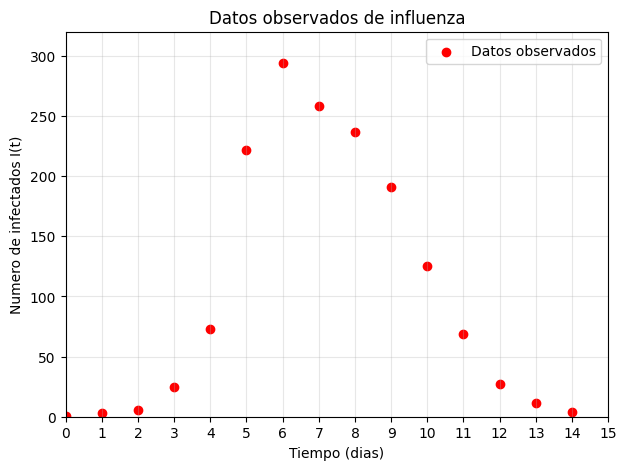

In [3]:
import numpy as np  # Se usa para manejar datos
import matplotlib.pyplot as plt  # Se usa para graficar

# Datos observados del articulo
t_datos = np.arange(0, 15)

# Se introcucen los datos de los infectados 
# Convierte los valores en un arreglo de Numpy
I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237,
    191, 125, 69, 27, 11, 4
])

# Se grafcan los datos observados 
plt.figure(figsize=(7, 5))

# Genera la grafica de dispersion 
plt.scatter(
    t_datos,
    I_datos,
    color="red",
    label="Datos observados"
)

# Se colocan los nombres de los ejes y un titulo 
plt.xlabel("Tiempo (dias)")
plt.ylabel("Numero de infectados I(t)")
plt.title("Datos observados de influenza")

# Se establecen los limites de los ejes 
plt.xlim(0, 15)
plt.ylim(0, 320)

# Se definen las marcas de los ejes 
plt.xticks(np.arange(0, 16, 1))
plt.yticks(np.arange(0, 321, 50))

plt.grid(alpha=0.3)
plt.legend()

plt.show()

# 2.Programar la solución numérica del modelo SIR con parámetros libres

Tenemos los valores: 

$$a = 0.00205$$

$$b = 0.43552$$

Sustituyendo estos valores en el sistema:

$$\frac{dS}{dt} = -0.00205 SI$$

$$\frac{dI}{dt} = 0.00205 SI - 0.43552 I$$

$$\frac{dR}{dt} = 0.43552 I$$

Para conocer cómo comienza la evolución de la epidemia, evaluamos las derivadas en $t = 0$.

Primera ecuación: susceptibles

$$S'(0) = -0.00205(762)(1)$$

$$S'(0) = -1.5621$$

Esto indica que inicialmente el número de susceptibles disminuye a una tasa de aproximadamente $1.5621$ estudiantes por día.

Segunda ecuación: infectados

$$I'(0) = 0.00205(762)(1) - 0.43552(1)$$

$$I'(0) = 1.5621 - 0.43552$$

$$I'(0) = 1.12658$$

Esto indica que inicialmente el número de infectados aumenta a una tasa de aproximadamente $1.12658$ estudiantes por día.

Tercera ecuación: recuperados

$$R'(0) = 0.43552(1)$$

$$R'(0) = 0.43552$$

Esto indica que inicialmente el número de recuperados aumenta a una tasa de $0.43552$ estudiantes por día.

Parametro a = 0.002180667267864487
Parametro b = 0.4452202565796441


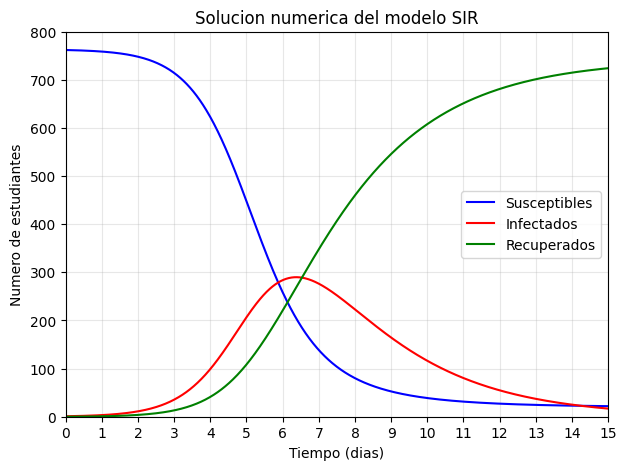

In [4]:
import numpy as np   # Se usa para usar arreglos con sdatos
import matplotlib.pyplot as plt    # Se usa para graficar
from scipy.integrate import solve_ivp  # Resuelve numericamente el sistema de ecuaciones
from scipy.optimize import least_squares  # Estima los parametros que minimizan las datos observados

# Genera los dias 
t_datos = np.arange(0, 15)

# Introduce los datos observados 
I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237,
    191, 125, 69, 27, 11, 4
])

# Se define el istema SIR
def modelo_SIR(t, y, a, b):

    S, I, R = y

    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I

    return [dSdt, dIdt, dRdt]


# Se resuelve el sistema SIR
def resolver_SIR(a, b, t):

# Establce la poblacion y las condiciones iniciales    
    N = 763

    I0 = 1
    S0 = N - I0
    R0 = 0

    y0 = [S0, I0, R0]
    # Se resuelve el sistema de ecuaciones
    solucion = solve_ivp(
        modelo_SIR,
        [0, 15],
        y0,
        args=(a, b),
        t_eval=t,
        rtol=1e-9,
        atol=1e-9
    )

    return solucion.y


# Se calculan las diferencias entre el modelo y los datos 
def residuos(parametros):

    a, b = parametros

    S, I, R = resolver_SIR(a, b, t_datos)

    return I - I_datos


# Se estimar los parametros libres
ajuste = least_squares(    #Utiliza el metodo de minimos cuadrados para encontrar los valores de a, b que mejor se ajusten 
    residuos,
    # Valores iniciales 
    x0=[0.002, 0.4],
    bounds=(0, np.inf)  # Establece que los parametros no pueden ser negativos
)

a, b = ajuste.x   # Valores estimados

print("Parametro a =", a)
print("Parametro b =", b)


t = np.linspace(0, 15, 1000)

# Resuelvel el sistema con los valores a, b que encontro
S, I, R = resolver_SIR(a, b, t)


# Graficar las soluciones
plt.figure(figsize=(7, 5))

plt.plot(t, S, color="blue",
         label="Susceptibles")

plt.plot(t, I, color="red",
         label="Infectados")

plt.plot(t, R, color="green",
         label="Recuperados")

plt.xlabel("Tiempo (dias)")
plt.ylabel("Numero de estudiantes")
plt.title("Solucion numerica del modelo SIR")

# Se establecen los limites
plt.xlim(0, 15)
plt.ylim(0, 800)

plt.xticks(np.arange(0, 16, 1))
plt.yticks(np.arange(0, 801, 100))

plt.grid(alpha=0.3)
plt.legend()

plt.show()

# 3. Plantear un ajuste por mínimos cuadrados $X(a, b)$

El objetivo de este punto es construir una función chi cuadrada que permita medir la diferencia entre los datos observados del brote de influenza y los valores calculados mediante el modelo SIR.

La solución numérica proporciona $I_{\text{modelo}}(t; a, b)$, que representa la cantidad de estudiantes infectados estimada por el modelo.

Para cada día $t_i$, definimos el residuo:

$$e_i(a, b) = I_{\text{datos}}(t_i) - I_{\text{modelo}}(t_i; a, b)$$

La función objetivo de mínimos cuadrados queda definida como:

$$\chi^2(a, b) = \sum_{i=0}^{14} [I_{\text{datos}}(t_i) - I_{\text{modelo}}(t_i; a, b)]^2$$

Esta expresión es la suma de los cuadrados de los residuos, denominada aquí $\chi^2$ no ponderada.

El objetivo del ajuste será encontrar:

$$(a^*, b^*) = \arg\min_{a>0,\, b>0} \chi^2(a, b)$$

Es decir, los valores de $a$ y $b$ que minimicen la diferencia entre los datos observados y los calculados.

PARAMETROS INICIALES
a = 0.00205
b = 0.43552
Error cuadratico = 10644.072983380687

PARAMETROS AJUSTADOS
a optimo = 0.0021806674071921657
b optimo = 0.4452202799592417
Error cuadratico = 4507.076254373361


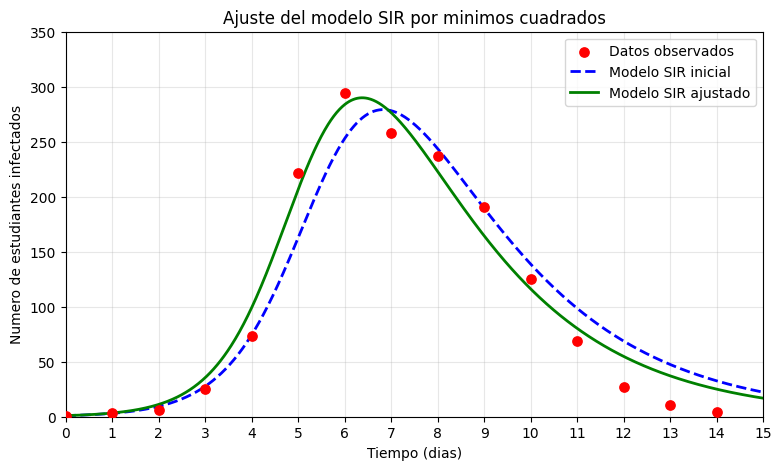

In [7]:

import numpy as np        # Se usa con arreglos de numeros
import matplotlib.pyplot as plt    # Se usa para graficar 
from scipy.integrate import solve_ivp   # Resuelve numericamente sistema de ecuaciones
from scipy.optimize import least_squares     # Estima los parametros que minimizan las datos observados

# Se introducen los datos observados 
t_datos = np.arange(0, 15)

I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237,
    191, 125, 69, 27, 11, 4
])

# Se define el sistema de ecuaciones SIR
def modelo_SIR(t, y, a, b):

    S, I, R = y

    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I

    return [dSdt, dIdt, dRdt]

# Se resueleve el sistema con parametros libres 
def resolver_SIR(a, b, t):

    # Se establece la poblacion y las condiciones iniciales 
    N = 763

    I0 = 1
    S0 = N - I0
    R0 = 0

    y0 = [S0, I0, R0]

    # Se resuelve el sistema de ecuaciones
    solucion = solve_ivp( # Lo resuelve usando valores especificos de a, b 
        modelo_SIR,
        [0, 15],
        y0,
        args=(a, b),
        t_eval=t,
        rtol=1e-9,
        atol=1e-9
    )

    if not solucion.success:
        raise RuntimeError(solucion.message)

    return solucion.y

# Define la funcion objetivo de minimos cuadrados 
# El objetivo es encontrar los parametros a y b que produzcan el menor error posible
def X(a, b):

    S, I, R = resolver_SIR(a, b, t_datos)

    errores = I_datos - I

    return np.sum(errores**2)

# Se define la funcion de residuos 
def residuos(parametros):

    a, b = parametros

    S, I, R = resolver_SIR(a, b, t_datos)

    return I_datos - I

# Se usan los valores iniciales del articulo 
a_inicial = 0.00205
b_inicial = 0.43552

X_inicial = X(a_inicial, b_inicial)

# Hace el ajuste por minimos cuadrados
resultado = least_squares(
    residuos,
    x0=[a_inicial, b_inicial],
    bounds=([1e-10, 1e-10], [np.inf, np.inf]),  # Establece las restricciones 
    xtol=1e-12,
    ftol=1e-12,
    gtol=1e-12
)

# Obtiene los parametros ajustados 
a_optimo, b_optimo = resultado.x

# Calcula el error cuadratico utilizando los parametros optimizados
X_minimo = X(a_optimo, b_optimo)

print("PARAMETROS INICIALES")
print("a =", a_inicial)
print("b =", b_inicial)
print("Error cuadratico =", X_inicial)

print("\nPARAMETROS AJUSTADOS")
print("a optimo =", a_optimo)
print("b optimo =", b_optimo)
print("Error cuadratico =", X_minimo)

# Genera puntos en los dias 
t = np.linspace(0, 15, 1000)

# Resuelve el modelo con los parametros iniciales
S_inicial, I_inicial, R_inicial = resolver_SIR(
    a_inicial, b_inicial, t
)

# Resuelve el modelo pero con los parametros obtenidos
S_ajustado, I_ajustado, R_ajustado = resolver_SIR(
    a_optimo, b_optimo, t
)

plt.figure(figsize=(9, 5))

plt.scatter(
    t_datos, I_datos,
    color="red",
    s=45,
    label="Datos observados",
    zorder=3
)

plt.plot(
    t, I_inicial,
    color="blue",
    linewidth=2,
    linestyle="--",
    label="Modelo SIR inicial"
)

plt.plot(
    t, I_ajustado,
    color="green",
    linewidth=2,
    label="Modelo SIR ajustado"
)

plt.xlabel("Tiempo (dias)")
plt.ylabel("Numero de estudiantes infectados")
plt.title("Ajuste del modelo SIR por minimos cuadrados")

plt.xlim(0, 15)
plt.ylim(0, 350)

plt.xticks(np.arange(0, 16, 1))
plt.yticks(np.arange(0, 351, 50))

plt.grid(alpha=0.3)
plt.legend()

plt.show()

# 4. Usar el método MCMC (Metropolis - Hastings) para optimizar $X$

Para utilizar Metropolis-Hastings, definimos una distribución objetivo proporcional a:

$$\pi(a, b) \propto \exp\left(-\frac{\chi^2(a, b)}{2\sigma^2}\right)$$

Aquí $\sigma$ representa una escala del error de las observaciones. Para este ejercicio utilizaremos $\sigma = 20$ como valor de prueba, no como una incertidumbre conocida del artículo.

Partimos de los parámetros de referencia:

$$a_0 = 0.00205, \quad b_0 = 0.43552$$

En cada iteración:

1. Se proponen nuevos parámetros $a'$ y $b'$ mediante pequeños cambios aleatorios.
2. Se resuelve el modelo SIR con esos parámetros.
3. Se calcula la nueva chi cuadrada $\chi^2(a', b')$.
4. Se calcula la probabilidad de aceptación:

$$P_{\text{aceptar}} = \min\left(1, \exp\left[-\frac{\chi^2(a', b') - \chi^2(a, b)}{2\sigma^2}\right]\right)$$

Si los parámetros nuevos producen una chi cuadrada menor, se aceptan siempre. Si producen una chi cuadrada mayor, todavía pueden aceptarse con cierta probabilidad.

RESULTADOS METROPOLIS-HASTINGS
a mejor = 0.0021816448434351346
b mejor = 0.44574743355052954
Chi cuadrada minima encontrada = 4507.590812921495
Porcentaje de aceptacion = 52.1 %


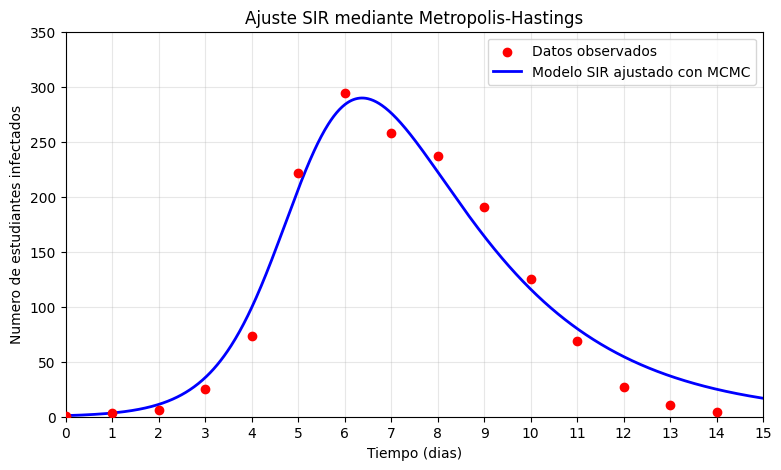

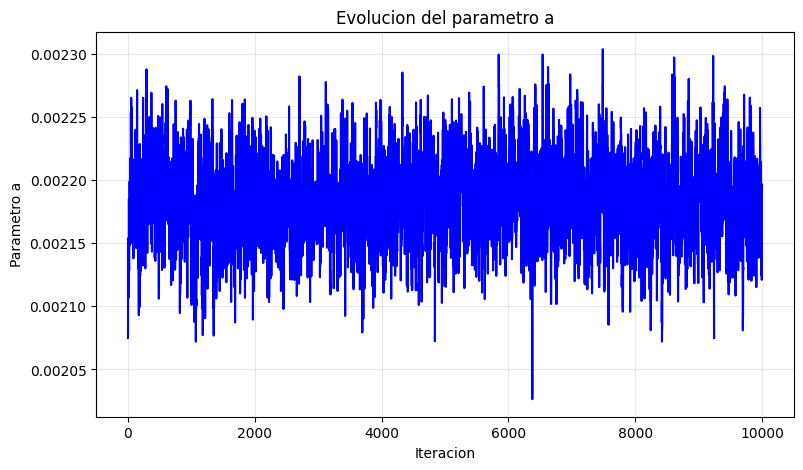

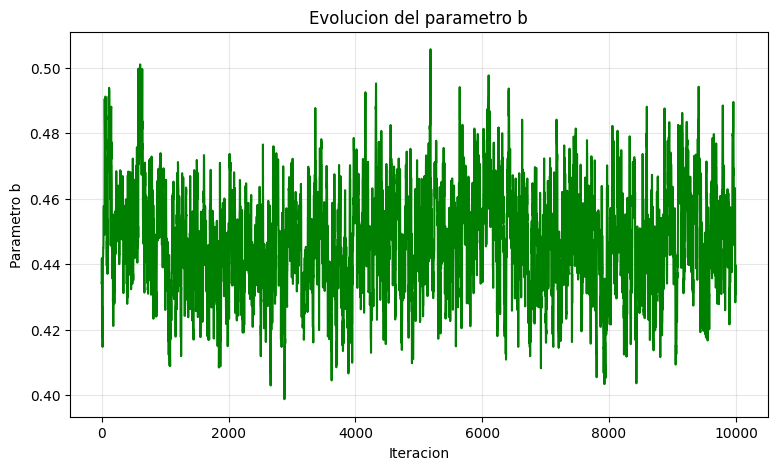

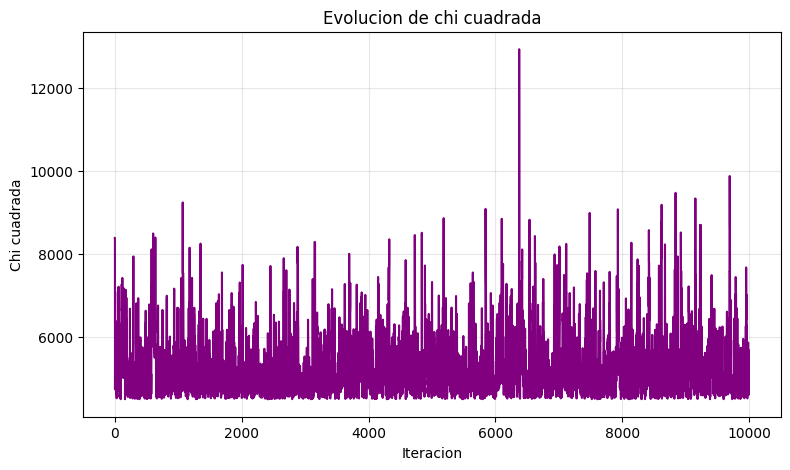

In [9]:
import numpy as np   # Se usa para arreglos
import matplotlib.pyplot as plt  # Se usa para graficar
from scipy.integrate import solve_ivp #Resuelve sistema de ecuaciones numericamente

# Se usan los datos observados 
t_datos = np.arange(0, 15)

I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237,
    191, 125, 69, 27, 11, 4
])

# Se define el sistema SIR
def modelo_SIR(t, y, a, b):

    S, I, R = y

    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I

    return [dSdt, dIdt, dRdt]

# Se soluciona numericamente con parametros libres 
def resolver_SIR(a, b, t):

    N = 763

    I0 = 1
    S0 = N - I0
    R0 = 0

    y0 = [S0, I0, R0]

    solucion = solve_ivp(
        modelo_SIR,
        [0, 15],
        y0,
        args=(a, b),
        t_eval=t,
        rtol=1e-8,
        atol=1e-8
    )

    if not solucion.success:
        raise RuntimeError(solucion.message)

    return solucion.y

# Se define la funcion chi que mide que tan bien se ajusta el modelo a los datos
def chi_cuadrada(a, b):

    if a <= 0 or b <= 0:
        return np.inf

    # Resuelve el sistema usando los parametros a, b
    # Predice la cantidad de infectados del modelo en los mismos dias 
    S, I, R = resolver_SIR(a, b, t_datos)

    errores = I_datos - I   # Calcula cada dato observado y cada prediccion 

    return np.sum(errores**2)

# Se usan los valores iniciales 
a_actual = 0.00205
b_actual = 0.43552

# Calcula el error correspondiente a los parametros iniciales
chi_actual = chi_cuadrada(a_actual, b_actual)

# Se usa Metropolis-Hastings
#Se establece una semilla para generar numeros aleatorios
np.random.seed(42)

n_iteraciones = 10000

# Controlan el tamaño de los cambios aleatorios 
paso_a = 0.00005
paso_b = 0.01

# Desviacion estandar 
# Su valor influye en la probabilidad de aceptar o rechazar nuevas propuestas
sigma = 20.0

# Almacenan la evolucion del los parametros y del error 
cadena_a = np.zeros(n_iteraciones)
cadena_b = np.zeros(n_iteraciones)
cadena_chi = np.zeros(n_iteraciones)

# Se guardan los parametros actuales como los mejores encontrados 
a_mejor = a_actual
b_mejor = b_actual
chi_mejor = chi_actual

aceptadas = 0

# Se usa Metropolis-Hastings
for i in range(n_iteraciones):

    # Propone nuevos parametros
    a_nuevo = a_actual + np.random.normal(0, paso_a)
    b_nuevo = b_actual + np.random.normal(0, paso_b)

    # Evalua la propuesta
    if a_nuevo > 0 and b_nuevo > 0:

        chi_nuevo = chi_cuadrada(a_nuevo, b_nuevo)

        # Calcula la robabilidad de aceptación
        log_alpha = -(chi_nuevo - chi_actual) / (2 * sigma**2)

        # Se acepta o rechaza
        if np.log(np.random.rand()) < min(0, log_alpha): # compara un número aleatorio uniforme con la probabilidad de aceptación

            a_actual = a_nuevo
            b_actual = b_nuevo
            chi_actual = chi_nuevo

            aceptadas += 1

    # Despues de aceptar o rechzar, guarda los parametros
    cadena_a[i] = a_actual
    cadena_b[i] = b_actual
    cadena_chi[i] = chi_actual

    # Se verifica si el error actual es menor que el mejor error encontrado
    if chi_actual < chi_mejor:

        chi_mejor = chi_actual
        a_mejor = a_actual
        b_mejor = b_actual

print("RESULTADOS METROPOLIS-HASTINGS")

print("a mejor =", a_mejor)
print("b mejor =", b_mejor)
print("Chi cuadrada minima encontrada =", chi_mejor)

print(
    "Porcentaje de aceptacion =",
    100 * aceptadas / n_iteraciones,
    "%"
)

# Resuelve el sistema con los mejores parametros
t = np.linspace(0, 15, 1000)

# Resuelve el sistema con los parametros encontrados
S, I, R = resolver_SIR(a_mejor, b_mejor, t)

# Grafica del ajuste 
plt.figure(figsize=(9, 5))

plt.scatter(
    t_datos, I_datos,
    color="red",
    label="Datos observados",
    zorder=3
)

plt.plot(
    t, I,
    color="blue",
    linewidth=2,
    label="Modelo SIR ajustado con MCMC"
)

plt.xlabel("Tiempo (dias)")
plt.ylabel("Numero de estudiantes infectados")
plt.title("Ajuste SIR mediante Metropolis-Hastings")

plt.xlim(0, 15)
plt.ylim(0, 350)

plt.xticks(np.arange(0, 16, 1))

plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Graficas de las cadenas de los parametros 
plt.figure(figsize=(9, 5))

plt.plot(cadena_a, color="blue")
plt.xlabel("Iteracion")
plt.ylabel("Parametro a")
plt.title("Evolucion del parametro a")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(9, 5))

plt.plot(cadena_b, color="green")
plt.xlabel("Iteracion")
plt.ylabel("Parametro b")
plt.title("Evolucion del parametro b")
plt.grid(alpha=0.3)
plt.show()

# Grafica de como cambia el errir cuadratico 
plt.figure(figsize=(9, 5))

plt.plot(cadena_chi, color="purple")
plt.xlabel("Iteracion")
plt.ylabel("Chi cuadrada")
plt.title("Evolucion de chi cuadrada")
plt.grid(alpha=0.3)
plt.show()
